<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 14: Unfolded RNN Architecture Visualization

1. Build a SimpleRNN and extract weights

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

tf.keras.utils.set_random_seed(42)

words = ["I", "love", "deep", "learning", "models"]
x = np.eye(5, dtype='float32').reshape(1,5,5)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(5,5)),
    tf.keras.layers.SimpleRNN(3, return_sequences=True),
    tf.keras.layers.Dense(1)
])

y = model(x)
Wx, Wh, b = model.layers[0].get_weights()
Wy, by = model.layers[1].get_weights()

print("Input weights:", Wx.shape)
print("Recurrent weights:", Wh.shape)
print("Output weights:", Wy.shape)


Input weights: (5, 3)
Recurrent weights: (3, 3)
Output weights: (3, 1)


2. Compute hidden states manually and verify with Keras

In [2]:

h = np.zeros(3)
manual = []

for t in range(5):
    h = np.tanh(x[0,t] @ Wx + h @ Wh + b)
    manual.append(h.copy())

manual = np.array(manual)

hidden_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)

keras_h = hidden_model(x).numpy()[0]

print("Manual hidden states:\n", np.round(manual,3))
print("Keras hidden states:\n", np.round(keras_h,3))
print("Match:", np.allclose(manual,keras_h,atol=1e-5))


Manual hidden states:
 [[ 0.68  -0.031  0.431]
 [ 0.676 -0.146 -0.518]
 [-0.101 -0.459 -0.246]
 [-0.661 -0.497 -0.215]
 [-0.299  0.564 -0.513]]
Keras hidden states:
 [[ 0.68  -0.031  0.431]
 [ 0.676 -0.146 -0.518]
 [-0.101 -0.459 -0.246]
 [-0.661 -0.497 -0.215]
 [-0.299  0.564 -0.513]]
Match: True


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 5, 5))
  warnings.warn(msg)


3. Draw the unfolded RNN using NetworkX

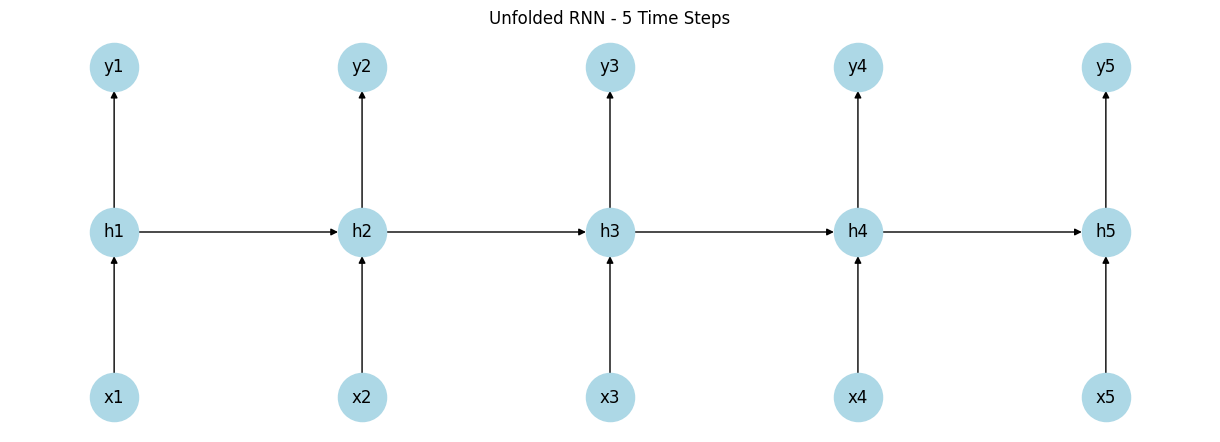

In [3]:

G = nx.DiGraph()
pos = {}

for i in range(1,6):
    pos[f'x{i}'] = (i,0)
    pos[f'h{i}'] = (i,1)
    pos[f'y{i}'] = (i,2)

    G.add_edge(f'x{i}',f'h{i}')
    G.add_edge(f'h{i}',f'y{i}')

    if i > 1:
        G.add_edge(f'h{i-1}',f'h{i}')

plt.figure(figsize=(12,4))
nx.draw(G,pos,with_labels=True,node_color='lightblue',
        node_size=1200,arrows=True,font_size=12)
plt.title("Unfolded RNN - 5 Time Steps")
plt.show()


4. Label edges with shared weights

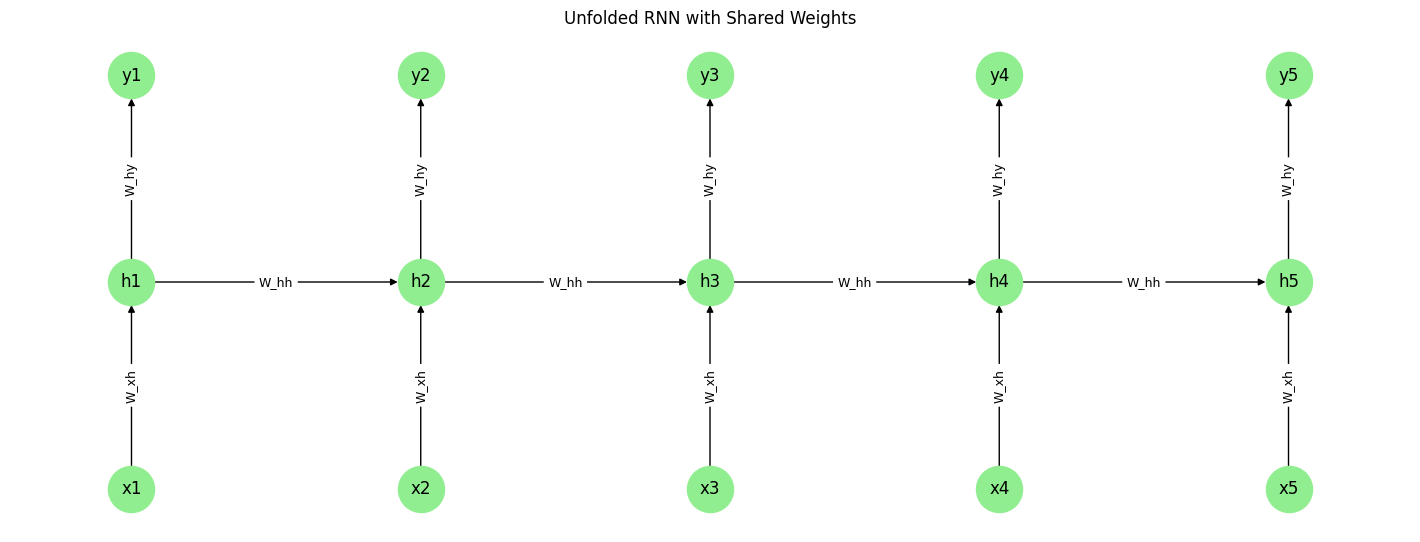

In [4]:

labels = {}

for i in range(1,6):
    labels[(f'x{i}',f'h{i}')] = 'W_xh'
    labels[(f'h{i}',f'y{i}')] = 'W_hy'
    if i > 1:
        labels[(f'h{i-1}',f'h{i}')] = 'W_hh'

plt.figure(figsize=(14,5))
nx.draw(G,pos,with_labels=True,node_color='lightgreen',
        node_size=1100,arrows=True)
nx.draw_networkx_edge_labels(G,pos,edge_labels=labels,
                            font_size=9)
plt.title("Unfolded RNN with Shared Weights")
plt.show()


5. Plot hidden-state values across time steps

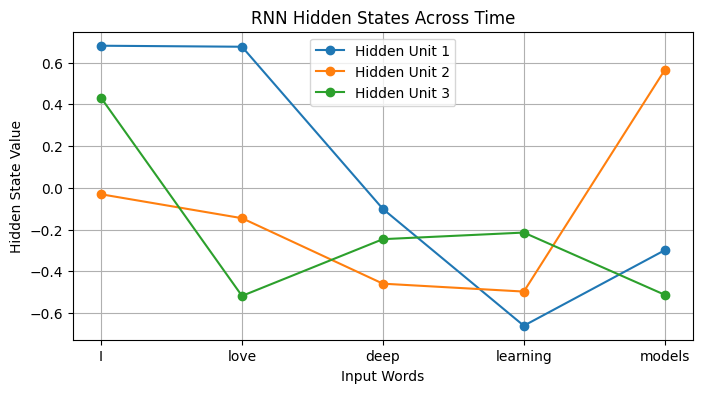

In [5]:

plt.figure(figsize=(8,4))

for i in range(3):
    plt.plot(range(1,6),manual[:,i],
             marker='o',label=f'Hidden Unit {i+1}')

plt.xticks(range(1,6),words)
plt.xlabel("Input Words")
plt.ylabel("Hidden State Value")
plt.title("RNN Hidden States Across Time")
plt.legend()
plt.grid(True)
plt.show()
